In [5]:
# Tools for tables, numbers and charts
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Tools for clustering
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

import os
os.environ["OMP_NUM_THREADS"] = "1"

# Load the customer data
df = pd.read_csv("Mall_Customers.csv")
print("Rows and columns:", df.shape)
df.head()

Rows and columns: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [6]:
# Check column types and missing values
df.info()
print("\nMissing values:")
print(df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB

Missing values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


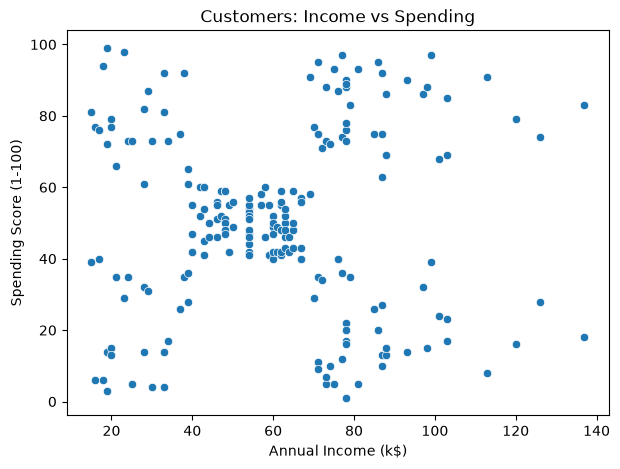

In [7]:
# Each dot is one customer: how much they earn vs how much they spend
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="Annual Income (k$)", y="Spending Score (1-100)")
plt.title("Customers: Income vs Spending")
plt.show()

In [8]:
## Data Check & EDA
- 200 customers, 5 columns, no missing values.
- The income vs spending chart shows about 5 visible groups: one in the middle and four in the corners.
- We will use **Annual Income** and **Spending Score** to make the groups.

SyntaxError: invalid syntax (1666073135.py, line 2)

C:\Users\User\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\User\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\User\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\User\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows wi

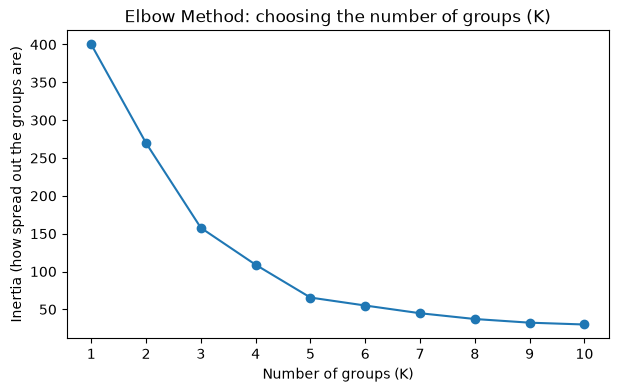

In [9]:
# 1. Pick the two columns we want to group by
X = df[["Annual Income (k$)", "Spending Score (1-100)"]]

# 2. Put both columns on the same scale (the measuring cup)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Try K = 1 to 10 and record how "spread out" the groups are
inertia = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(X_scaled)
    inertia.append(km.inertia_)

# 4. Draw the Elbow chart
plt.figure(figsize=(7, 4))
plt.plot(range(1, 11), inertia, marker="o")
plt.title("Elbow Method: choosing the number of groups (K)")
plt.xlabel("Number of groups (K)")
plt.ylabel("Inertia (how spread out the groups are)")
plt.xticks(range(1, 11))
plt.show()

In [ ]:
## Elbow Method
Inertia drops sharply up to K = 5, then flattens.
Adding more groups after 5 barely improves the fit, so **K = 5** is the best number of groups.

In [10]:
# Run K-Means with 5 groups (5 flags)
kmeans = KMeans(n_clusters=5, n_init=10, random_state=42)

# Give every customer a group number (0 to 4)
df["Cluster"] = kmeans.fit_predict(X_scaled)

# How many customers are in each group?
print(df["Cluster"].value_counts().sort_index())
df.head()

Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


C:\Users\User\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4


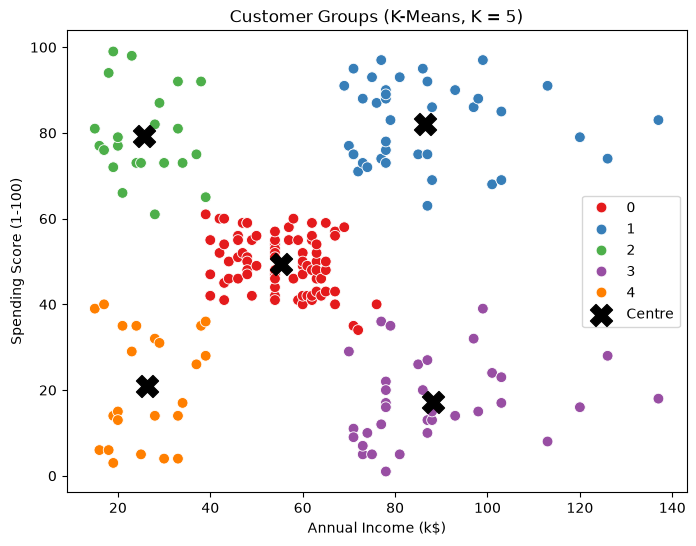

In [11]:
# Find the centre (flag position) of each group, back in normal units
centers = scaler.inverse_transform(kmeans.cluster_centers_)

# Draw every customer, coloured by their group
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="Annual Income (k$)", y="Spending Score (1-100)",
                hue="Cluster", palette="Set1", s=60)

# Draw the flags (group centres) as big black X marks
plt.scatter(centers[:, 0], centers[:, 1], c="black", s=250, marker="X", label="Centre")

plt.title("Customer Groups (K-Means, K = 5)")
plt.legend()
plt.show()

In [12]:
# Average income, spending and age for each group
profile = df.groupby("Cluster")[["Annual Income (k$)", "Spending Score (1-100)", "Age"]].mean().round(1)
profile["Customers"] = df["Cluster"].value_counts().sort_index()
profile

,Annual Income (k$),Spending Score (1-100),Age,Customers
Cluster,,,,
0,55.3,49.5,42.7,81
1,86.5,82.1,32.7,39
2,25.7,79.4,25.3,22
3,88.2,17.1,41.1,35
4,26.3,20.9,45.2,23


## Customer Groups
| Cluster | Name | Income | Spending | What the mall should do |
|---|---|---|---|---|
| 0 | Average Customers | Medium | Medium | Regular promotions and loyalty points |
| 1 | VIP / Big Spenders | High | High | VIP offers, premium products, early access |
| 2 | Young Impulse Buyers | Low | High | Discounts and trendy, affordable items |
| 3 | Careful Rich | High | Low | Persuade them with quality and exclusive deals |
| 4 | Budget Savers | Low | Low | Budget deals and essentials |

## Conclusion
- The Elbow Method showed K = 5 is the best number of groups.
- K-Means split the 200 customers into 5 clear groups based on income and spending.
- The biggest group (81 customers) is average customers; the most valuable group for the mall is Cluster 1 (high income, high spending).
- Next idea: add Age as a third feature to see if the groups change.